# Industry Project: "I'm Not Sure, Send It to a Human": Document Routing with Conformal Prediction (Production-Style)

> **Who is this notebook for?** Beginners who have trained a classifier and want to know how companies use it **safely**: let the model decide when it is sure, and hand the rest to people.
> Every step is explained in plain English and almost every line of code has a comment.

---

### How this notebook is different from `01_conformal_prediction.ipynb`

| `01_conformal_prediction.ipynb` | This notebook |
|---|---|
| Theory of nonconformity scores, regression intervals, `MAPIE` | One business decision: **automate or send to a human?** |
| Iris / California housing | Real text documents (20 Newsgroups) routed to 8 specialist teams, with confusable topics |
| Checks overall coverage | Chooses `alpha` from the **review team's capacity**, checks **per-class** coverage, compares with the usual "confidence threshold" baseline, prices the decision in $ |
| Ends with prediction sets | Ends with a saved router, a serving function, label-free monitoring and tests |

---

### The business problem

A technical support company receives about **2,000 incoming documents per day** (emails, forum posts, tickets). Each one must go to one of **8 specialist teams** (PC hardware, Mac hardware, X-Windows software, electronics, cars, motorcycles, medicine, space).

- A **misrouted** document costs about **$25**: the wrong team reads it, forwards it, and the customer waits a day longer.
- A **triage clerk** can check a document for about **$1.50**, but the triage team can only handle **35% of the daily volume** (700 documents).
- Today the clerks route everything by hand and are overloaded.

The model will never be perfect (some PC and Mac hardware questions are genuinely ambiguous). So the goal is **not** "maximise accuracy", but:

> *Automate the documents where the model is reliably right, send the uncertain ones to the clerks, stay within their capacity, and keep the error rate of automated decisions low and **measurable**.*

**Conformal prediction** gives us exactly this: instead of one label, the model outputs a **set** of plausible teams with a guarantee like *"the true team is in the set for at least 90% of documents"*. If the set has **one** team, we route automatically. If it has several (or none), a human decides, and the set becomes their shortlist.

### Table of Contents
1. Setup and config
2. Get the data: 8 support queues
3. Split: train / calibration / test
4. Baseline classifier (TF-IDF + logistic regression)
5. Split conformal prediction with the LAC score
6. Does the guarantee hold? Coverage over many random splits
7. Choose alpha from the review team's capacity
8. Automation rate vs error rate, and the money
9. Is conformal better than a simple confidence threshold? (honest comparison)
10. Per-class coverage and Mondrian (class-conditional) conformal
11. APS: adaptive sets for the human shortlist
12. When the guarantee breaks: distribution shift
13. Save the router with its metadata
14. Serving: confident label or "route to human"
15. Monitoring without labels + automated tests
16. Summary, exercises and resources

---
## 1. Setup and config

In [1]:
import json
import logging
import tempfile
import time
import warnings
from dataclasses import dataclass, asdict
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
log = logging.getLogger("routing")


@dataclass(frozen=True)
class Config:
    random_state: int = 42
    docs_per_day: int = 2_000
    review_capacity: float = 0.35          # clerks can check 35% of daily documents
    cost_misroute: float = 25.0            # $ per wrongly auto-routed document
    cost_review: float = 1.50              # $ per document checked by a clerk
    human_error_rate: float = 0.03         # clerks are good but not perfect
    calibration_share: float = 0.5         # half of the held-out documents calibrate, half test


CFG = Config()
print(CFG)

Config(random_state=42, docs_per_day=2000, review_capacity=0.35, cost_misroute=25.0, cost_review=1.5, human_error_rate=0.03, calibration_share=0.5)


---
## 2. Get the data: 8 support queues

We use the classic **20 Newsgroups** dataset (real posts from the 1990s) as a stand-in for incoming documents, keeping 8 groups as our 8 specialist teams. It is bundled with scikit-learn and cached locally, so no internet is needed. We remove headers, signatures and quoted replies (`remove=...`) so the model can't cheat by reading e.g. the newsgroup name in the header; that is the realistic setting, an incoming email doesn't tell you its team.

In a company, this would be a query on the ticket system: `SELECT body, final_team FROM tickets WHERE closed_at >= '2026-01-01'` (using the team that **finally** solved the ticket as the label).

In [2]:
TEAMS = {   # newsgroup -> business name of the team
    "comp.sys.ibm.pc.hardware": "pc_hardware", "comp.sys.mac.hardware": "mac_hardware",
    "comp.windows.x": "x_windows", "sci.electronics": "electronics", "rec.autos": "cars",
    "rec.motorcycles": "motorcycles", "sci.med": "medicine", "sci.space": "space",
}


def load_documents(subset: str) -> pd.DataFrame:
    raw = fetch_20newsgroups(subset=subset, categories=list(TEAMS), remove=("headers", "footers", "quotes"),
                             random_state=CFG.random_state, download_if_missing=True)
    df = pd.DataFrame({"text": raw.data, "team": [TEAMS[raw.target_names[t]] for t in raw.target]})
    df["text"] = df["text"].str.strip()
    return df


history = load_documents("train")        # older documents (the "bydate" split is ordered in time)
recent = load_documents("test")          # newer documents
# Data cleaning: empty messages (only a quote or a signature) can't be routed by any model
for name, df in [("history", history), ("recent", recent)]:
    print(f"{name}: {len(df):,} docs, {int((df['text'].str.len() < 20).sum())} nearly empty")
history = history[history["text"].str.len() >= 20].reset_index(drop=True)
recent = recent[recent["text"].str.len() >= 20].reset_index(drop=True)
print(history["team"].value_counts().to_string())

history: 4,731 docs, 156 nearly empty
recent: 3,149 docs, 121 nearly empty
team
x_windows       588
pc_hardware     578
motorcycles     577
space           576
medicine        576
electronics     573
cars            556
mac_hardware    551


> In production, nearly empty documents would be routed to a human **by rule**, before the model is even called. Rules for the obvious cases + a model for the rest is a very common design.

---
## 3. Split: train / calibration / test

Conformal prediction needs **three** sets:

| Set | Used for | Here |
|---|---|---|
| Train | fit the classifier | the older documents |
| **Calibration** | measure how wrong the model is on unseen data → compute the conformal threshold | half of the newer documents |
| Test | check the guarantee and the business numbers, once | the other half |

The guarantee assumes calibration and future documents are **exchangeable** (come from the same distribution, in any order). That is why calibration data must be **recent** and must not be used for training. Section 12 shows what happens when this assumption breaks.

In [3]:
calib, test = train_test_split(recent, train_size=CFG.calibration_share, stratify=recent["team"],
                               random_state=CFG.random_state)
CLASSES = np.array(sorted(TEAMS.values()))                       # fixed order of the 8 teams
to_index = {team: i for i, team in enumerate(CLASSES)}
y_train = history["team"].map(to_index).values
y_calib = calib["team"].map(to_index).values
y_test = test["team"].map(to_index).values
print(f"train {len(history):,} | calibration {len(calib):,} | test {len(test):,}")

train 4,575 | calibration 1,514 | test 1,514


---
## 4. Baseline classifier (TF-IDF + logistic regression)

For text routing, **TF-IDF + logistic regression** is the standard first model: fast, strong, explainable (you can list the words behind each team), and it outputs probabilities. Conformal prediction works on top of **any** model that outputs scores, so you could later swap in a fine-tuned transformer without changing anything else in this notebook.

In [4]:
router_model = Pipeline([
    ("tfidf", TfidfVectorizer(sublinear_tf=True, min_df=2, max_features=50_000, stop_words="english")),
    ("clf", LogisticRegression(C=10, max_iter=1000)),
])
start = time.time()
router_model.fit(history["text"], y_train)
log.info("Trained in %.1fs", time.time() - start)

proba_calib = router_model.predict_proba(calib["text"])           # shape (n_docs, 8)
proba_test = router_model.predict_proba(test["text"])
print(f"Test accuracy (always trust the top team): {accuracy_score(y_test, proba_test.argmax(1)):.1%}")
print(classification_report(y_test, proba_test.argmax(1), target_names=CLASSES, digits=3))

2026-10-21 16:59:31,636 | INFO | Trained in 38.8s


Test accuracy (always trust the top team): 80.4%
              precision    recall  f1-score   support

        cars      0.784     0.822     0.802       185
 electronics      0.683     0.654     0.668       191
mac_hardware      0.833     0.730     0.778       185
    medicine      0.871     0.853     0.862       190
 motorcycles      0.770     0.874     0.819       191
 pc_hardware      0.792     0.817     0.804       191
       space      0.809     0.809     0.809       188
   x_windows      0.898     0.870     0.884       193

    accuracy                          0.804      1514
   macro avg      0.805     0.804     0.803      1514
weighted avg      0.805     0.804     0.803      1514



About four out of five documents are routed correctly. The per-team table shows where the model struggles: **electronics** and **Mac hardware** have the lowest scores (they overlap with PC hardware and with each other). Fully automating would misroute roughly one document in five, about 400 per day: far too many. Sending everything to humans exceeds their capacity. We need something in between.

---
## 5. Split conformal prediction with the LAC score

The recipe (Least Ambiguous set-valued Classifier, *LAC*, Sadinle et al. 2019) in plain words:

1. For each **calibration** document, compute a **nonconformity score**: `score = 1 − (probability the model gave to the TRUE team)`. Small score = the model was confident and right; large score = the model was surprised.
2. Pick the threshold `q̂` = the `(1 − α)` quantile of these scores (with a small `(n+1)/n` correction for finite samples).
3. For a **new** document, the prediction set contains every team whose probability is at least `1 − q̂`.

**The guarantee:** the true team is in the set for at least `1 − α` of future documents (e.g. 90% for α = 0.1), whatever the model, as long as the data is exchangeable. The model can be bad; then the sets are just bigger.

In [5]:
def conformal_quantile(scores: np.ndarray, alpha: float) -> float:
    """Finite-sample corrected (1 - alpha) quantile of calibration scores."""
    n = len(scores)
    level = min(1.0, np.ceil((n + 1) * (1 - alpha)) / n)
    return float(np.quantile(scores, level, method="higher"))


def lac_threshold(proba_cal: np.ndarray, y_cal: np.ndarray, alpha: float) -> float:
    scores = 1 - proba_cal[np.arange(len(y_cal)), y_cal]       # 1 - p(true class)
    return conformal_quantile(scores, alpha)


def lac_sets(proba: np.ndarray, qhat: float) -> np.ndarray:
    """Boolean matrix (n_docs, n_classes): True = team is in the prediction set."""
    return proba >= 1 - qhat


def set_metrics(sets: np.ndarray, y: np.ndarray, proba: np.ndarray) -> dict:
    size = sets.sum(axis=1)
    auto = size == 1                                              # exactly one team -> automate
    auto_wrong = auto & (proba.argmax(1) != y)
    return {"coverage": sets[np.arange(len(y)), y].mean(), "avg_set_size": size.mean(),
            "automation_rate": auto.mean(), "empty_sets": (size == 0).mean(),
            "error_rate_automated": auto_wrong.sum() / max(auto.sum(), 1)}


ALPHA_DEMO = 0.10
qhat_demo = lac_threshold(proba_calib, y_calib, ALPHA_DEMO)
sets_demo = lac_sets(proba_test, qhat_demo)
print(f"alpha = {ALPHA_DEMO} -> qhat = {qhat_demo:.3f}: a team enters the set if its probability >= {1 - qhat_demo:.3f}")
print({k: round(float(v), 3) for k, v in set_metrics(sets_demo, y_test, proba_test).items()})

for i in range(4):                                              # what the sets look like for a few documents
    members = CLASSES[sets_demo[i]].tolist()
    print(f"\n[{CLASSES[y_test[i]]:12s}] set={members}  text: {test['text'].iloc[i][:110]!r}")

alpha = 0.1 -> qhat = 0.838: a team enters the set if its probability >= 0.162
{'coverage': 0.898, 'avg_set_size': 1.417, 'automation_rate': 0.657, 'empty_sets': 0.001, 'error_rate_automated': 0.065}

[cars        ] set=['cars', 'electronics', 'pc_hardware']  text: 'Or do like the manual says and put it in 3rd first, then you can quickly\ngo into reverse... no waiting.\n\nmark'

[motorcycles ] set=['cars', 'motorcycles']  text: 'Black ones look better.  None are truely indiginous to America,\nalthough some of the finest are produced here.'

[space       ] set=['medicine', 'space']  text: '1. Please take this out of sci.space.\n\n2. Ayn Rand was not only born in Russia, but educated there. A lot\nof h'

[mac_hardware] set=['mac_hardware']  text: "...\n\n\nYes, that is what it sounds like to me, too. But before I spend\nda bucks, I want to make sure I'm right."


The coverage on the test set is close to the promised 90%. Notice how the size of the set tells you **how hard** the document is: clear documents get one team, ambiguous ones get two or three.

---
## 6. Does the guarantee hold? Coverage over many random splits

The guarantee is about the **average over many calibration sets**. On one particular split, coverage can be a bit above or below 90%. To check it honestly, we repeat the calibration/test split 500 times (re-using the model's probabilities, which is cheap) and look at the distribution of the test coverage.

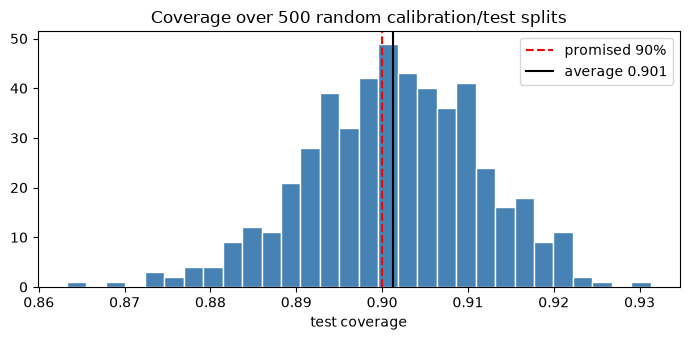

mean coverage 0.901 | 5th-95th percentile 0.884 - 0.917 | splits below 0.88: 2.4%


In [6]:
proba_recent = np.vstack([proba_calib, proba_test])               # all held-out probabilities
y_recent = np.concatenate([y_calib, y_test])
rng = np.random.default_rng(CFG.random_state)
coverages = []
for _ in range(500):
    perm = rng.permutation(len(y_recent))
    cal_idx, tst_idx = perm[: len(y_calib)], perm[len(y_calib):]
    q = lac_threshold(proba_recent[cal_idx], y_recent[cal_idx], ALPHA_DEMO)
    coverages.append(lac_sets(proba_recent[tst_idx], q)[np.arange(len(tst_idx)), y_recent[tst_idx]].mean())
coverages = np.array(coverages)

plt.figure(figsize=(7, 3.5))
plt.hist(coverages, bins=30, color="steelblue", edgecolor="white")
plt.axvline(1 - ALPHA_DEMO, color="red", ls="--", label="promised 90%")
plt.axvline(coverages.mean(), color="black", label=f"average {coverages.mean():.3f}")
plt.xlabel("test coverage"); plt.title("Coverage over 500 random calibration/test splits")
plt.legend(); plt.tight_layout(); plt.show()
print(f"mean coverage {coverages.mean():.3f} | 5th-95th percentile {np.percentile(coverages, 5):.3f}"
      f" - {np.percentile(coverages, 95):.3f} | splits below 0.88: {(coverages < 0.88).mean():.1%}")

On average the coverage is at (or slightly above) 90%, as promised. Individual splits vary by about ±1.5 percentage points with ~1,500 calibration documents (and a few percent of splits land below 88%); with fewer calibration documents the spread grows. **Rule of thumb:** use at least several hundred, preferably 1,000+, calibration examples.

---
## 7. Choose alpha from the review team's capacity

Here is the business translation of α:
- **small α** (e.g. 0.02): very high coverage → bigger sets → fewer singletons → **more work for clerks**, very few automated errors;
- **large α** (e.g. 0.25): small sets → more automation → **more automated errors**.

The clerks can review at most **35%** of documents. So we pick the **smallest α** whose review rate (documents with a set size other than 1) fits within the capacity. We make this choice on the **calibration** data and only *check* it on the test data. (Strictly speaking, choosing α and computing `q̂` on the same data is slightly optimistic; with a large calibration set the effect is small, and the test set tells us whether it mattered.)

2026-10-21 16:59:37,454 | INFO | Chosen alpha = 0.10 (target coverage 90%), qhat = 0.838


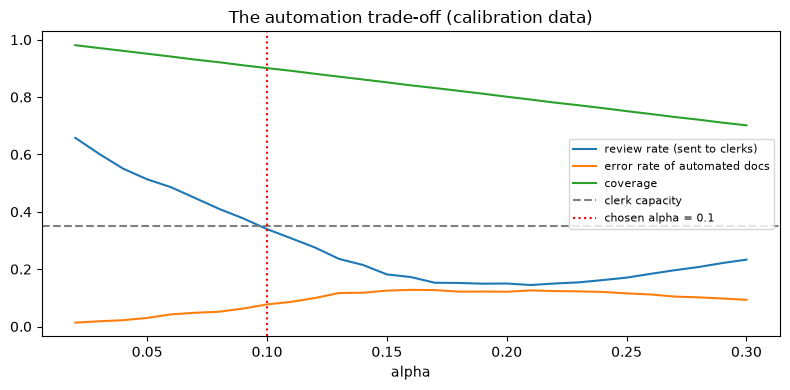

,qhat,coverage,avg_set_size,automation_rate,empty_sets,error_rate_automated,review_rate
alpha,,,,,,,
0.02,0.942,0.981,3.095,0.342,0.000,0.014,0.658
0.05,0.894,0.951,1.972,0.487,0.000,0.030,0.513
0.10,0.838,0.901,1.410,0.661,0.001,0.077,0.339
0.20,0.721,0.801,0.969,0.850,0.090,0.121,0.150
0.30,0.600,0.701,0.779,0.767,0.227,0.093,0.233


In [7]:
ALPHAS = np.round(np.arange(0.02, 0.301, 0.01), 2)
rows = []
for a in ALPHAS:
    q = lac_threshold(proba_calib, y_calib, a)
    m = set_metrics(lac_sets(proba_calib, q), y_calib, proba_calib)
    rows.append({"alpha": a, "qhat": q, **m, "review_rate": 1 - m["automation_rate"]})
alpha_table = pd.DataFrame(rows).set_index("alpha")

feasible = alpha_table[alpha_table["review_rate"] <= CFG.review_capacity]
ALPHA = float(feasible.index.min())                             # smallest alpha that fits the capacity
QHAT = lac_threshold(proba_calib, y_calib, ALPHA)
log.info("Chosen alpha = %.2f (target coverage %.0f%%), qhat = %.3f", ALPHA, (1 - ALPHA) * 100, QHAT)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(alpha_table.index, alpha_table["review_rate"], label="review rate (sent to clerks)")
ax.plot(alpha_table.index, alpha_table["error_rate_automated"], label="error rate of automated docs")
ax.plot(alpha_table.index, alpha_table["coverage"], label="coverage")
ax.axhline(CFG.review_capacity, color="grey", ls="--", label="clerk capacity")
ax.axvline(ALPHA, color="red", ls=":", label=f"chosen alpha = {ALPHA}")
ax.set_xlabel("alpha"); ax.legend(fontsize=8); ax.set_title("The automation trade-off (calibration data)")
plt.tight_layout(); plt.show()
alpha_table.loc[sorted({0.02, 0.05, 0.1, ALPHA, 0.2, 0.3})].round(3)

---
## 8. Automation rate vs error rate, and the money

Now we check the chosen operating point on the **test** set and translate it into a daily cost, comparing with the two obvious alternatives:
- **automate everything** (always trust the top team);
- **clerks check everything** (impossible today because of the capacity, but a useful reference).

In [8]:
def daily_cost(review_rate: float, auto_error_rate: float, cfg: Config = CFG) -> dict:
    """Expected daily cost of a routing policy for cfg.docs_per_day documents."""
    reviewed = review_rate * cfg.docs_per_day
    automated = cfg.docs_per_day - reviewed
    misrouted = automated * auto_error_rate + reviewed * cfg.human_error_rate
    cost = reviewed * cfg.cost_review + misrouted * cfg.cost_misroute
    return {"reviewed_per_day": round(reviewed), "misrouted_per_day": round(misrouted, 1),
            "cost_per_day_$": round(cost), "within_capacity": review_rate <= cfg.review_capacity + 1e-9}


test_sets = lac_sets(proba_test, QHAT)
test_m = set_metrics(test_sets, y_test, proba_test)
top1_error = 1 - accuracy_score(y_test, proba_test.argmax(1))
policies = pd.DataFrame({
    "automate everything": {"review_rate": 0.0, "auto_error": top1_error} | daily_cost(0.0, top1_error),
    "clerks check everything": {"review_rate": 1.0, "auto_error": np.nan} | daily_cost(1.0, 0.0),
    f"conformal LAC (alpha={ALPHA})": {"review_rate": 1 - test_m["automation_rate"],
                                       "auto_error": test_m["error_rate_automated"]}
                                      | daily_cost(1 - test_m["automation_rate"], test_m["error_rate_automated"]),
}).T
print(f"Test coverage at alpha={ALPHA}: {test_m['coverage']:.3f} (target >= {1 - ALPHA:.2f})")
policies

Test coverage at alpha=0.1: 0.898 (target >= 0.90)


,review_rate,auto_error,reviewed_per_day,misrouted_per_day,cost_per_day_$,within_capacity
automate everything,0.0,0.196169,0,392.3,9808,True
clerks check everything,1.0,NaN,2000,60.0,4500,False
conformal LAC (alpha=0.1),0.342801,0.065327,686,106.4,3689,True


The conformal policy stays (close to) within the clerks' capacity, automates the rest, and keeps the error rate of automated decisions far below the ~20% of "automate everything". Its daily cost is the lowest of the three, and, unlike "clerks check everything", it is actually feasible with today's team.

---
## 9. Is conformal better than a simple confidence threshold? (honest comparison)

Many teams already do *"if the top probability is below 0.8, send to a human"*. Is conformal prediction better? To compare fairly, we tune that threshold on the calibration set so it sends **the same share** of documents to clerks, and compare the error rate of the automated documents on the test set.

In [9]:
review_share = 1 - set_metrics(lac_sets(proba_calib, QHAT), y_calib, proba_calib)["automation_rate"]
max_p_calib = proba_calib.max(1)
conf_threshold = float(np.quantile(max_p_calib, review_share))    # same review rate on calibration
auto_thr = proba_test.max(1) >= conf_threshold
comparison = pd.DataFrame({
    "conformal LAC (singleton = automate)": {"review_rate": 1 - test_m["automation_rate"],
                                             "error_rate_automated": test_m["error_rate_automated"]},
    f"max-probability >= {conf_threshold:.3f}": {"review_rate": 1 - auto_thr.mean(),
                                                "error_rate_automated": (proba_test.argmax(1)[auto_thr] != y_test[auto_thr]).mean()},
}).T.round(4)
comparison

,review_rate,error_rate_automated
conformal LAC (singleton = automate),0.3428,0.0653
max-probability >= 0.521,0.3527,0.0612


**Honest result:** at the same review rate, the two policies make almost the same decisions. That is not a coincidence: a LAC set contains exactly one team when one probability is above `1 − q̂` and all others are below it, which is very close to "top probability above a threshold".

So what does conformal prediction add, if not better automation?
1. **A principled, auditable threshold:** `q̂` comes with a coverage statement ("the true team is in the set 90% of the time") that you can verify, report to auditors, and monitor. A hand-picked 0.8 has no such meaning.
2. **A shortlist for the human:** reviewers don't start from 8 teams; they see the 2-3 plausible ones (next cell).
3. **Guarantees per class** with the Mondrian variant (Section 10), which a single global threshold can't give.
4. It works on top of **any** model and is robust to badly calibrated probabilities (the sets adapt).

In [10]:
reviewed = test_sets.sum(1) != 1
shortlist_size = test_sets[reviewed].sum(1)
in_shortlist = test_sets[reviewed][np.arange(reviewed.sum()), y_test[reviewed]]
print(f"Documents sent to clerks: {reviewed.mean():.1%}")
print(f"  average shortlist size: {shortlist_size.mean():.2f} teams (instead of {len(CLASSES)})")
print(f"  true team is in the shortlist: {in_shortlist.mean():.1%}  | empty sets: {(shortlist_size == 0).mean():.1%}")

Documents sent to clerks: 34.3%
  average shortlist size: 2.22 teams (instead of 8)
  true team is in the shortlist: 82.9%  | empty sets: 0.2%


---
## 10. Per-class coverage and Mondrian (class-conditional) conformal

The 90% guarantee is **marginal**: on average over all documents. It can hide that one team's documents are covered only 80% of the time while easy teams get 98%. For the business that matters: if all the hard electronics questions are the ones that get misrouted, the electronics team suffers.

**Mondrian conformal prediction** fixes this by computing a **separate threshold per class**, using only the calibration documents of that class. Then the guarantee holds **for every team**: "for each team, its documents get the right team in the set at least 1 − α of the time". The price: slightly bigger sets for the hard teams, and you need enough calibration documents **per class**.

In [11]:
def mondrian_thresholds(proba_cal: np.ndarray, y_cal: np.ndarray, alpha: float) -> np.ndarray:
    """One LAC threshold per class, computed on that class's calibration documents only."""
    return np.array([lac_threshold(proba_cal[y_cal == k], y_cal[y_cal == k], alpha) for k in range(len(CLASSES))])


def mondrian_sets(proba: np.ndarray, qhats: np.ndarray) -> np.ndarray:
    return proba >= 1 - qhats[None, :]                           # class k uses its own threshold


def per_class_coverage(sets: np.ndarray, y: np.ndarray) -> pd.Series:
    covered = sets[np.arange(len(y)), y]
    return pd.Series({CLASSES[k]: covered[y == k].mean() for k in range(len(CLASSES))})


QHATS_MONDRIAN = mondrian_thresholds(proba_calib, y_calib, ALPHA)
sets_mondrian = mondrian_sets(proba_test, QHATS_MONDRIAN)
per_class = pd.DataFrame({
    "test_docs": pd.Series(y_test).map(dict(enumerate(CLASSES))).value_counts(),
    "coverage_marginal_LAC": per_class_coverage(test_sets, y_test),
    "coverage_mondrian": per_class_coverage(sets_mondrian, y_test),
    "mondrian_threshold_p>=": pd.Series(1 - QHATS_MONDRIAN, index=CLASSES),
}).round(3)
print(f"Target coverage per class: {1 - ALPHA:.2f}")
print("Overall:", {"marginal": round(float(set_metrics(test_sets, y_test, proba_test)["avg_set_size"]), 2),
                   "mondrian": round(float(set_metrics(sets_mondrian, y_test, proba_test)["avg_set_size"]), 2)},
      "(average set size)")
per_class.sort_values("coverage_marginal_LAC")

Target coverage per class: 0.90
Overall: {'marginal': 1.42, 'mondrian': 1.52} (average set size)


,test_docs,coverage_marginal_LAC,coverage_mondrian,mondrian_threshold_p>=
mac_hardware,185,0.811,0.854,0.111
electronics,191,0.848,0.906,0.099
cars,185,0.892,0.886,0.164
space,188,0.904,0.878,0.188
x_windows,193,0.907,0.886,0.217
pc_hardware,191,0.921,0.895,0.181
medicine,190,0.926,0.926,0.150
motorcycles,191,0.974,0.953,0.183


Read the `coverage_marginal_LAC` column from the top: the hardest teams (Mac hardware, electronics) are clearly below the target, the easy ones (motorcycles, medicine) above it, even though the overall average is fine. Mondrian **narrows the spread**: the worst team rises from about 81% to about 85%, electronics reaches the target, and the easy teams come down towards 90%. It is not perfect on this test set: with only ~190 calibration and ~190 test documents per team, each per-team number has a noise of roughly ±2-4 percentage points, and the guarantee holds on average over calibration draws, not on every single split. More calibration data per team makes it tighter. Its sets are a bit larger on average, which means slightly more work for the clerks: a typical **fairness vs efficiency** trade-off that the business should choose consciously. (Mondrian is also used for fairness across customer groups: compute thresholds per region or language instead of per class.)

---
## 11. APS: adaptive sets for the human shortlist

LAC gives the **smallest** sets on average, but it treats every document the same way. **APS** (Adaptive Prediction Sets, Romano et al. 2020) builds the set by adding teams from most to least likely **until their total probability reaches the threshold**. Uncertain documents (flat probabilities) get larger sets, confident ones smaller sets. That often gives better coverage on hard documents, at the cost of bigger sets overall.

We use the simple, non-randomized version: the score of a document is the total probability of all teams ranked at or above the true team.

In [12]:
def aps_cumulative(proba: np.ndarray) -> np.ndarray:
    """For each doc and class: sum of probabilities of all classes ranked at or above that class."""
    order = np.argsort(-proba, axis=1)                          # classes from most to least likely
    sorted_p = np.take_along_axis(proba, order, axis=1)
    cum_sorted = np.cumsum(sorted_p, axis=1)
    cum = np.empty_like(proba)
    np.put_along_axis(cum, order, cum_sorted, axis=1)           # back to the original class order
    return cum


def aps_threshold(proba_cal, y_cal, alpha) -> float:
    return conformal_quantile(aps_cumulative(proba_cal)[np.arange(len(y_cal)), y_cal], alpha)


def aps_sets(proba, qhat) -> np.ndarray:
    return aps_cumulative(proba) <= qhat


QHAT_APS = aps_threshold(proba_calib, y_calib, ALPHA)
sets_aps = aps_sets(proba_test, QHAT_APS)
hard = proba_test.max(1) < 0.5                                   # documents where the model is unsure
summary = {}
for name, s in [("LAC", test_sets), ("Mondrian LAC", sets_mondrian), ("APS", sets_aps)]:
    m = set_metrics(s, y_test, proba_test)
    summary[name] = {"coverage": m["coverage"], "avg_set_size": m["avg_set_size"],
                     "automation_rate": m["automation_rate"], "error_rate_automated": m["error_rate_automated"],
                     "coverage_on_hard_docs": s[hard][np.arange(hard.sum()), y_test[hard]].mean(),
                     "worst_class_coverage": per_class_coverage(s, y_test).min()}
print(f"'Hard' documents (top probability < 0.5): {hard.mean():.1%} of the test set")
pd.DataFrame(summary).T.round(3)

'Hard' documents (top probability < 0.5): 33.4% of the test set


,coverage,avg_set_size,automation_rate,error_rate_automated,coverage_on_hard_docs,worst_class_coverage
LAC,0.898,1.417,0.657,0.065,0.772,0.811
Mondrian LAC,0.898,1.520,0.600,0.062,0.778,0.854
APS,0.892,4.810,0.052,0.000,0.980,0.808


How to choose (based on the table above):
- **LAC** for the **automation decision**: smallest sets, so the most singletons for the same α.
- **APS** typically covers the **hard** documents better and gives larger shortlists; good when the shortlist is shown to a human and missing the right team is costly. If its automation rate is too low for your capacity, you would have to raise α.
- **Mondrian** when each team (or customer group) needs its **own** guarantee.

In this run the difference is extreme: APS covers **98%** of the hard documents (LAC: 77%), but its sets contain almost 5 teams on average and it would automate only about 5% of documents. Useless for the automation decision, useful as a "don't miss the right team" shortlist. Many production systems therefore combine them: LAC (or Mondrian LAC) decides automate-vs-review, APS builds the reviewer's shortlist.

---
## 12. When the guarantee breaks: distribution shift

The guarantee needs **exchangeability**: future documents must look like the calibration documents. Suppose the company opens a new **mobile contact form** where customers type only a short sentence. We simulate it by keeping only the first 12 words of each test document.

In [13]:
def first_words(text: str, n: int = 12) -> str:
    return " ".join(text.split()[:n])


short_test_text = test["text"].map(first_words)
proba_short = router_model.predict_proba(short_test_text)
shift_rows = {}
for name, proba, q in [("normal documents", proba_test, QHAT), ("short mobile messages", proba_short, QHAT)]:
    m = set_metrics(lac_sets(proba, q), y_test, proba)
    shift_rows[name] = {"accuracy": accuracy_score(y_test, proba.argmax(1)), **m}

# Fix: re-calibrate on a sample of short messages from the new channel (half of them), test on the other half
idx_cal, idx_tst = train_test_split(np.arange(len(y_test)), train_size=0.5, stratify=y_test, random_state=0)
q_short = lac_threshold(proba_short[idx_cal], y_test[idx_cal], ALPHA)
m = set_metrics(lac_sets(proba_short[idx_tst], q_short), y_test[idx_tst], proba_short[idx_tst])
shift_rows["short messages, re-calibrated"] = {"accuracy": accuracy_score(y_test[idx_tst], proba_short[idx_tst].argmax(1)), **m}
pd.DataFrame(shift_rows).T.round(3)

,accuracy,coverage,avg_set_size,automation_rate,empty_sets,error_rate_automated
normal documents,0.804,0.898,1.417,0.657,0.001,0.065
short mobile messages,0.551,0.672,1.678,0.450,0.002,0.279
"short messages, re-calibrated",0.552,0.926,4.494,0.139,0.000,0.057


On short messages the model is much weaker, and with the **old** threshold the coverage falls clearly below the promised level: the guarantee silently stopped holding, because the calibration data no longer represents the new documents. Notice the warning signs that appear **without labels**: the share of documents sent to review jumps (from about a third to about half) and the average set size grows.

**Re-calibrating** on a sample of labelled short messages restores the coverage (the model is the same; only `q̂` changes), but the sets become much bigger, so far fewer documents can be automated. The honest message to the business: *"for the new channel the model can automate much less; either accept more manual work or improve the model for short texts."*

---
## 13. Save the router with its metadata

The conformal threshold is part of the model. It must be saved together with the classifier, with the α it was computed for, the calibration data it came from and its validation numbers. If the classifier is retrained, the threshold **must be recomputed** on fresh calibration data.

In [14]:
ARTIFACT_DIR = Path(tempfile.mkdtemp(prefix="doc_router_"))      # real project: models/doc_router/v1/
joblib.dump(router_model, ARTIFACT_DIR / "router_pipeline.joblib")
metadata = {
    "model_name": "document_router", "model_version": "1.0.0",
    "trained_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "sklearn_version": sklearn.__version__, "classes": CLASSES.tolist(),
    "conformal": {"method": "split conformal, LAC score", "alpha": ALPHA, "qhat": QHAT,
                  "mondrian_qhats": dict(zip(CLASSES.tolist(), QHATS_MONDRIAN.round(4).tolist())),
                  "n_calibration_docs": int(len(y_calib)), "calibration_period": "newest documents (bydate test, half)"},
    "test_results": {k: round(float(v), 4) for k, v in test_m.items()},
    "business": asdict(CFG),
}
(ARTIFACT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2))
for f in ARTIFACT_DIR.iterdir():
    print(f"{f.name:24s} {f.stat().st_size / 1024:8.1f} KB")

metadata.json                 1.1 KB
router_pipeline.joblib     1823.0 KB


---
## 14. Serving: confident label or "route to human"

The service validates the input, computes the prediction set and returns a clear **action**. It never hides uncertainty: the reviewer gets the shortlist and the probabilities. Rules come first (empty or very short text goes straight to a human).

In [15]:
from pydantic import BaseModel, Field, ValidationError


class IncomingDocument(BaseModel):
    document_id: str = Field(min_length=1)
    text: str = Field(max_length=50_000)


class DocumentRouter:
    MIN_CHARS = 20                                                # business rule from Section 2

    def __init__(self, artifact_dir: Path):
        self.model = joblib.load(artifact_dir / "router_pipeline.joblib")
        self.meta = json.loads((artifact_dir / "metadata.json").read_text())
        self.classes = np.array(self.meta["classes"])
        self.qhat = self.meta["conformal"]["qhat"]

    def route(self, payload: dict) -> dict:
        doc = IncomingDocument(**payload)                         # raises ValidationError on bad input
        if len(doc.text.strip()) < self.MIN_CHARS:
            return {"document_id": doc.document_id, "action": "HUMAN_REVIEW", "reason": "text too short",
                    "shortlist": [], "model_version": self.meta["model_version"]}
        proba = self.model.predict_proba([doc.text])[0]
        in_set = proba >= 1 - self.qhat
        ranked = [(str(self.classes[k]), round(float(proba[k]), 3)) for k in np.argsort(-proba) if in_set[k]]
        if in_set.sum() == 1:
            return {"document_id": doc.document_id, "action": "AUTO_ROUTE", "team": ranked[0][0],
                    "probability": ranked[0][1], "model_version": self.meta["model_version"]}
        return {"document_id": doc.document_id, "action": "HUMAN_REVIEW",
                "reason": "model is unsure" if in_set.sum() > 1 else "no team is plausible enough",
                "shortlist": ranked, "model_version": self.meta["model_version"]}


router = DocumentRouter(ARTIFACT_DIR)
examples = [
    {"document_id": "T-1", "text": "My Kawasaki keeps stalling at idle after I changed the carburetor jets, any ideas for the bike?"},
    {"document_id": "T-2", "text": "Which SCSI controller works best? My drive is not recognised after boot, the jumper settings look fine."},
    {"document_id": "T-3", "text": "help!!"},
]
for e in examples:
    print(router.route(e))
try:
    router.route({"document_id": "", "text": "x" * 10})
except ValidationError as err:
    print("Rejected:", [e["loc"][0] for e in err.errors()])

{'document_id': 'T-1', 'action': 'AUTO_ROUTE', 'team': 'motorcycles', 'probability': 0.916, 'model_version': '1.0.0'}
{'document_id': 'T-2', 'action': 'AUTO_ROUTE', 'team': 'pc_hardware', 'probability': 0.908, 'model_version': '1.0.0'}
{'document_id': 'T-3', 'action': 'HUMAN_REVIEW', 'reason': 'text too short', 'shortlist': [], 'model_version': '1.0.0'}
Rejected: ['document_id']


---
## 15. Monitoring without labels + automated tests

In production you only learn the true team later (when a clerk or the specialist confirms it), and only for some documents. Two habits:

1. **Label-free signals, every day:** review rate, average set size, share of empty sets. They need no labels and react immediately to drift (Section 12 showed they jump on the short-message channel).
2. **Audit sample:** a random 2-5% of *automated* documents is checked by a clerk anyway, so the real error rate of automated decisions (and the coverage) is measured continuously.

In [16]:
def daily_monitoring(proba: np.ndarray, qhat: float, reference: dict) -> dict:
    """Label-free health check of a day of routing decisions vs the reference (test) values."""
    size = lac_sets(proba, qhat).sum(1)
    today = {"review_rate": float((size != 1).mean()), "avg_set_size": float(size.mean()),
             "empty_sets": float((size == 0).mean())}
    alerts = [k for k, v in today.items()
              if abs(v - reference[k]) > max(0.05, 0.25 * reference[k])]   # >25% relative (or 5 pp) change
    return {k: round(v, 3) for k, v in today.items()} | {"alerts": alerts}


reference = {"review_rate": 1 - test_m["automation_rate"], "avg_set_size": test_m["avg_set_size"],
             "empty_sets": test_m["empty_sets"]}
print("Normal day     :", daily_monitoring(proba_test[:300], QHAT, reference))
print("Mobile-form day:", daily_monitoring(proba_short[:300], QHAT, reference))

Normal day     : {'review_rate': 0.37, 'avg_set_size': 1.447, 'empty_sets': 0.0, 'alerts': []}
Mobile-form day: {'review_rate': 0.587, 'avg_set_size': 1.72, 'empty_sets': 0.0, 'alerts': ['review_rate']}


In [17]:
def test_coverage_close_to_target():
    assert test_m["coverage"] >= (1 - ALPHA) - 0.03, "coverage clearly below the promise"


def test_capacity_respected_on_test():
    assert 1 - test_m["automation_rate"] <= CFG.review_capacity + 0.05


def test_sets_grow_when_alpha_shrinks():
    sizes = [lac_sets(proba_test, lac_threshold(proba_calib, y_calib, a)).sum(1).mean() for a in (0.2, 0.1, 0.05)]
    assert sizes[0] <= sizes[1] <= sizes[2]


def test_router_handles_rules_and_auto_route():
    assert router.route({"document_id": "x", "text": "hi"})["action"] == "HUMAN_REVIEW"
    assert router.route(examples[0])["action"] in {"AUTO_ROUTE", "HUMAN_REVIEW"}


def test_monitoring_flags_shift():
    assert daily_monitoring(proba_short[:300], QHAT, reference)["alerts"], "drift not detected"


for test in [test_coverage_close_to_target, test_capacity_respected_on_test, test_sets_grow_when_alpha_shrinks,
             test_router_handles_rules_and_auto_route, test_monitoring_flags_shift]:
    test()
    print(f"PASSED  {test.__name__}")

PASSED  test_coverage_close_to_target
PASSED  test_capacity_respected_on_test
PASSED  test_sets_grow_when_alpha_shrinks
PASSED  test_router_handles_rules_and_auto_route
PASSED  test_monitoring_flags_shift


---
## 16. Summary, exercises and resources

| Industry practice | What we did | Where it's used |
|---|---|---|
| Human-in-the-loop by design | Singleton set → automate, otherwise → clerk with shortlist | Claims, tickets, KYC documents, content moderation, medical triage |
| Split conformal (LAC) | Calibration quantile of `1 − p(true)` | Any classifier, any library |
| Verify the guarantee | Coverage over 500 random splits | Model validation reports |
| α from capacity | Smallest α that fits the review team | Operations planning |
| Money view | Daily cost of automate-all vs review-all vs conformal | Business case |
| Honest baseline | Max-probability threshold at the same review rate | Avoid over-selling the method |
| Per-class guarantee | Mondrian conformal | Fairness across teams / groups |
| Adaptive shortlists | APS | Reviewer tooling |
| Distribution shift | Short-message channel breaks coverage; re-calibrate | New channels, new markets |
| Monitoring | Label-free set-size signals + audit sample | Production dashboards |

### Practice exercises
1. Change `review_capacity` to 0.20 and 0.50. How do α, the error rate of automated documents and the daily cost change?
2. Replace logistic regression with `sklearn.naive_bayes.ComplementNB`. Accuracy drops, but does coverage still hold? What happens to the set sizes?
3. Implement the **randomized** APS score (add `U * p(true)` with `U ~ Uniform(0, 1)`) and compare set sizes.
4. Install MAPIE (`pip install MAPIE==1.4.1`, as pinned in `requirements.txt`) and reproduce our LAC sets with `SplitConformalClassifier(conformity_score="lac")`.
5. Make Mondrian thresholds per **text length bucket** (short / medium / long) instead of per class. Does it help on the mobile channel?

### Resources (checked)
- Angelopoulos & Bates, *A Gentle Introduction to Conformal Prediction and Distribution-Free Uncertainty Quantification*: https://arxiv.org/abs/2107.07511
- Romano, Sesia, Candès, *Classification with Valid and Adaptive Coverage* (APS): https://arxiv.org/abs/2006.02544
- Sadinle, Lei, Wasserman, *Least Ambiguous Set-Valued Classifiers with Bounded Error Levels* (LAC): https://arxiv.org/abs/1609.00451
- MAPIE docs, comparison of LAC and APS for classification: https://mapie.readthedocs.io/en/stable/generated/classification/2-advanced-analysis/plot_comp_methods_on_2d_dataset/
- Awesome Conformal Prediction (curated list of tutorials, papers, libraries): https://github.com/valeman/awesome-conformal-prediction
- scikit-learn 20 Newsgroups dataset: https://scikit-learn.org/stable/datasets/real_world.html#newsgroups-dataset

### Related notebooks in this repo
- Theory, regression intervals and MAPIE: `01_conformal_prediction.ipynb`
- Probability calibration: `../01_supervised/13_model_calibration.ipynb`
- Text classification basics: `../../07_NLP/03_text_classification.ipynb`
- Monitoring in production: `../../15_MLOps/06_monitoring/01_monitoring.ipynb`